# 03-单片机入门与开发环境

> 选对芯片，配齐工程，编译出固件，建立下载连接，再用运行结果验证整个链路。

这是「嵌入式单片机一套通关」十二篇笔记中的第 03 篇。前两篇解决 C 语言的语法和数据访问，本篇开始把 C 代码放进单片机工程，理解 MCU、ARM 内核、Keil、芯片支持包、固件库、启动文件和调试器分别负责什么。

本篇的实践目标是：**能打开并核对一个 GD32 工程，理解模板怎样搭建，完成 LED 闪烁程序的编译、下载与调试流程。** GPIO 的电气模式、输入采样和更多外设控制在第 04 篇展开。


## 1. 本篇范围与资料说明

| 课程内容 | 本篇整理重点 |
|---|---|
| 单片机概述 | MCU 的组成、存储器、总线和外设 |
| ARM介绍 | 架构、内核、芯片、开发板的层次 |
| 开发环境搭建 | Keil MDK、Compiler、GD32 DFP 与驱动 |
| 高级点灯工程师 | 读取原理图、GPIO 初始化、编译与烧录 |
| 库与包 | CMSIS、SPL、HAL、BSP 和软件分层 |
| 模板工程的搭建 | 文件目录、工程配置、启动与时钟、常见错误 |
| 支持资料 | 软件集合、原理图与手册集合、开发板自检 |

**课程来源：**[用户提供的知识库入口](https://www.yuque.com/embheima/mcu)，当前跳转到[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。已阅读上述六篇核心页面和三篇支持页面可访问的正文，并查看点灯原理图及模板的部分时钟、延时代码。

**阅读边界：**单片机概述页面中的 PPT 在线预览要求登录；本次使用其可访问正文，未读取 PPT 全文。网页中的模板压缩包、芯片手册 PDF 和全部截图未逐一下载验证。这里的说明、代码和自绘图为重新整理的配套学习内容，不声称与某个下载附件逐文件一致。

**本次完成的内容：**编写学习笔记、校对关键配置关系、检查文件结构与算例。本次没有安装 Keil、修改电脑驱动、编译 GD32 工程、连接开发板或烧录硬件。下文操作步骤是供学习时执行的流程，验收结果是预期标准。

**芯片选择约定：**本篇以课程自检页列出的 **GD32F407VET6 核心板**与 GD32F4xx 标准外设库为学习主线；环境安装页另有 GD32F450ZG，模板截图还出现其他型号。使用自己的板子时，先看芯片丝印和配套原理图，再选择匹配的工程配置，不将这些型号混用。


## 2. MCU 是什么：把计算与控制资源集成在一起

单片机通常称 MCU，即 Microcontroller Unit。它把 CPU 内核、存储器、时钟、复位、中断控制以及一批外设集成在一颗芯片中，适合完成采样、判断、通信和控制任务。

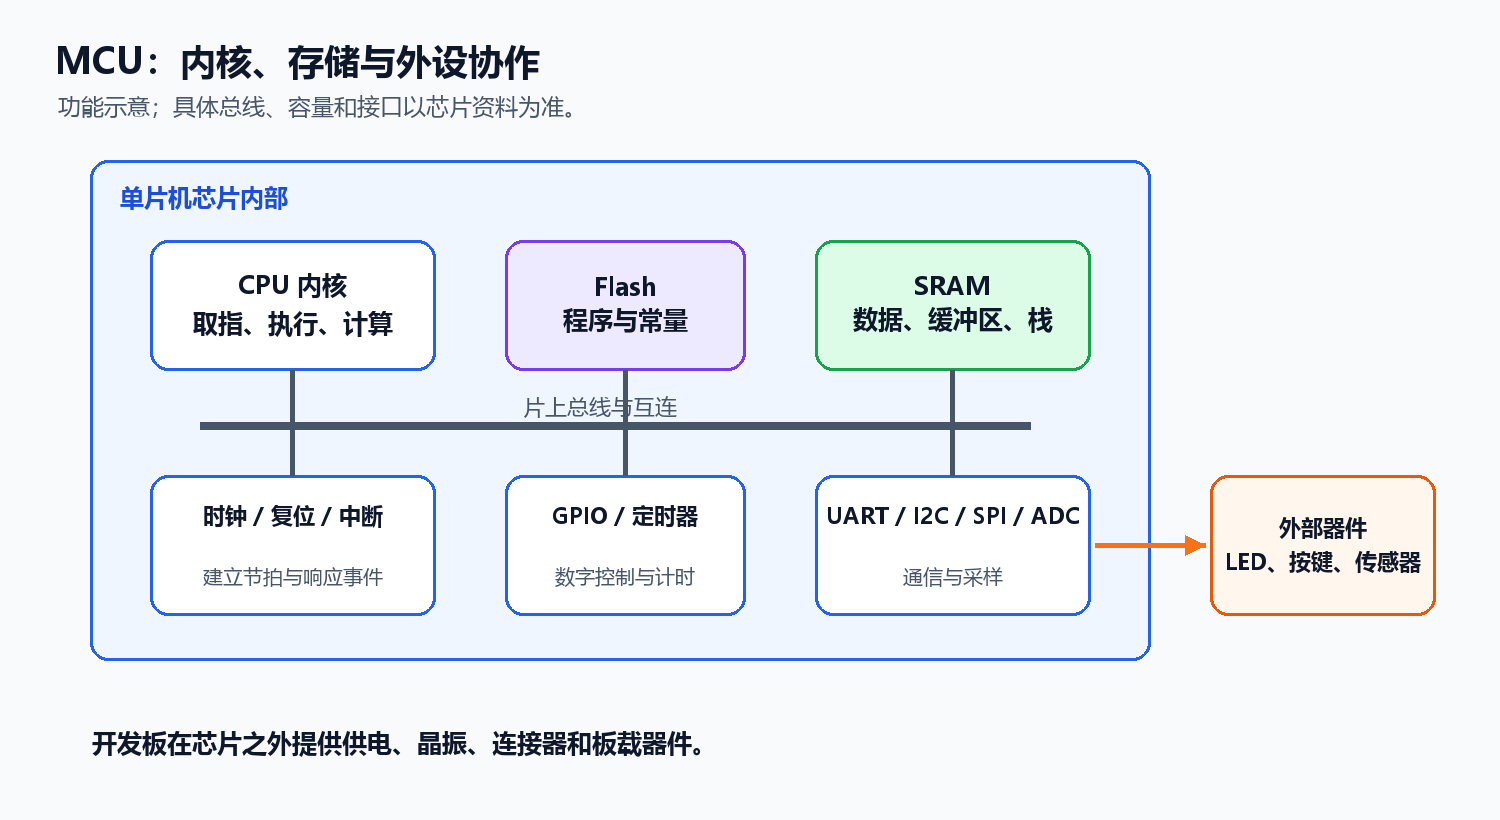

*自绘补充图：功能示意，不代表 GD32F407 内部总线的完整结构。*

| 组成 | 主要作用 | 在本课程中的例子 |
|---|---|---|
| CPU 内核 | 执行指令、计算、控制流程 | 执行 main 中的循环与函数 |
| Flash | 保存程序与适合放入其中的常量 | 下载后的固件通常存于片内 Flash |
| SRAM | 保存运行时可写数据 | 局部对象、全局数据、缓冲区、栈 |
| 时钟与复位 | 提供运行节拍、建立初始状态 | 晶振、PLL、RESET |
| 中断控制 | 响应外设和系统事件 | SysTick、串口、定时器事件 |
| GPIO | 数字输入输出或引脚复用 | LED、按键、通信引脚 |
| 定时器 | 计时、周期事件、PWM 等 | 周期任务与电机控制 |
| 通信外设 | 按接口时序收发数据 | UART、I2C、SPI |
| ADC 等模拟外设 | 将模拟输入转换为数字数据 | 电位器与传感器采集 |

“单片机”不等于“只有 CPU”，也不等于“一定没有操作系统”。简单程序可以裸机运行，更复杂的控制系统可以引入 RTOS；资源和软件架构由任务需求决定。

MPU、SoC、MCU 的实际产品边界有重叠。学习阶段把握用途即可：MCU 常强调片上控制资源、成本和功耗；应用处理器常面向复杂操作系统和较大外部存储。不能仅靠“32 位”或“用了 ARM”来区分。


## 3. CPU、存储器与总线怎样配合

CPU 取出指令，读写数据，再按程序控制外设。总线把 CPU、存储器和外设连接起来，承载地址、数据以及读写等控制信息。

| 信息 | 回答的问题 |
|---|---|
| 地址 | 要访问哪个位置或外设寄存器？ |
| 数据 | 本次读出了什么，或准备写入什么？ |
| 控制 | 是读还是写，什么时候传输，如何确认完成？ |

实际 MCU 的片上总线可能采用 AHB、APB、总线矩阵等结构，不一定就是三组独立导线的简单图。课程中的地址/数据/控制总线模型帮助理解功能，深入时以芯片框图与用户手册为准。

### 存储器映射外设

很多 MCU 把外设寄存器映射到地址空间中。CPU 访问规定地址，可以读取引脚状态或修改外设配置。固件库把这些访问包装成函数：

```c
rcu_periph_clock_enable(RCU_GPIOB);
gpio_bit_set(GPIOB, GPIO_PIN_2);
```

这是 GD32F4xx 标准外设库调用片段；它需要匹配的头文件、驱动实现和目标硬件。不能放进普通电脑上的 Hello World 工程，就期待控制板上的 PB2。

外设时钟、模式和复用配置会影响一次寄存器操作是否产生预期效果。“函数被调用”只是执行链路中的一步，后面还要检查硬件连接和输出电平。


## 4. ARM 架构、Cortex 内核、GD32 芯片与开发板

这几个名字处在不同层次：

| 层次 | 例子 | 表示什么 |
|---|---|---|
| 指令集架构 | Arm 的相关架构版本与配置 | 指令、寄存器和执行模型等约定 |
| CPU 内核设计 | Cortex-M4 | 按架构实现的处理器内核 |
| MCU 芯片 | GD32F407VET6 | 内核加存储器、外设、时钟、封装等 |
| 开发板 | 课程 GD32 核心板 | 芯片加供电、晶振、连接器和板载器件 |
| 扩展板 | 开天斧扩展板 | 屏幕、传感器、按键、电机等学习资源 |

GD32F407 使用 Cortex-M4 内核。选择 IDE 中的 Device 时，要选择具体 GD32 器件，而不是仅选择“Cortex-M4”就认为整个芯片已经配置完整。

### Cortex 系列的用途

| 系列 | 常见定位 | 学习时需要分清 |
|---|---|---|
| Cortex-A | 高性能应用处理 | 常与复杂操作系统、MMU 和较大存储配合 |
| Cortex-R | 强调实时性与可靠性的系统 | 与具体产品的实时和保护需求匹配 |
| Cortex-M | 微控制器应用 | 常见于控制、采样、低功耗与 RTOS 场景 |

不同 Cortex-M 内核在指令能力、DSP、浮点、缓存和安全特性上有差异。部分功能是可选项，芯片厂商的实现决定实际可用能力；不能把所有 M4 都视为完全相同，也不能认为所有 ARM 芯片都有 GPU、MMU 或虚拟内存。

内核型号也不规定芯片必须工作在某个频率区间。最大频率、电压条件和存储器等待周期，需要查询具体型号数据手册。

“32 位 MCU”不表示每个变量都占 32 位，也不意味着所有计算一条指令完成；C 数据类型、编译器生成指令以及具体实现共同影响结果。


## 5. 先读对资料：四种文档各有用途

| 文档 | 优先找什么 | 举例 |
|---|---|---|
| 芯片数据手册 Datasheet | 型号、封装、引脚、电气参数、容量与频率限制 | 我的芯片能用哪些引脚？供电范围是什么？ |
| 系列用户手册 User Manual | 外设工作模式、寄存器、时钟、复位和中断 | GPIO 配置位如何工作？ |
| 开发板原理图 | 芯片引脚连接到哪个器件、晶振与供电电路 | LED1 接 PB2 还是其他引脚？高电平是否点亮？ |
| 固件库使用指南与源码 | API 参数、函数实现、返回值与示例 | gpio_mode_set 的参数如何填写？ |

一个型号相近的用户手册可能覆盖系列共性，但封装引脚和容量必须与具体器件匹配。课程手册集合页明确列出了 GD32F407VET6 的资料，这是本篇主线依据。

### 型号与开发板核对清单

开始工程前记录：芯片完整丝印、核心板版本、晶振频率、LED 引脚与有效电平、供电入口、SWD 接口和下载器类型。

GD32F407VE 是工具界面中可能显示的器件名，GD32F407VET6 是板上完整订货型号。不要仅看到文件夹叫 GD32F4xx，便忽略具体器件差异。型号后缀含义以该型号官方命名表为准，不凭经验猜容量。

工程名称同样不能替代 Device 配置。课程截图里的工程文件名出现 GD32F470，不足以证明实际板子就是 F470；应查看工程选项和板上芯片。


## 6. 一条完整的单片机开发链路

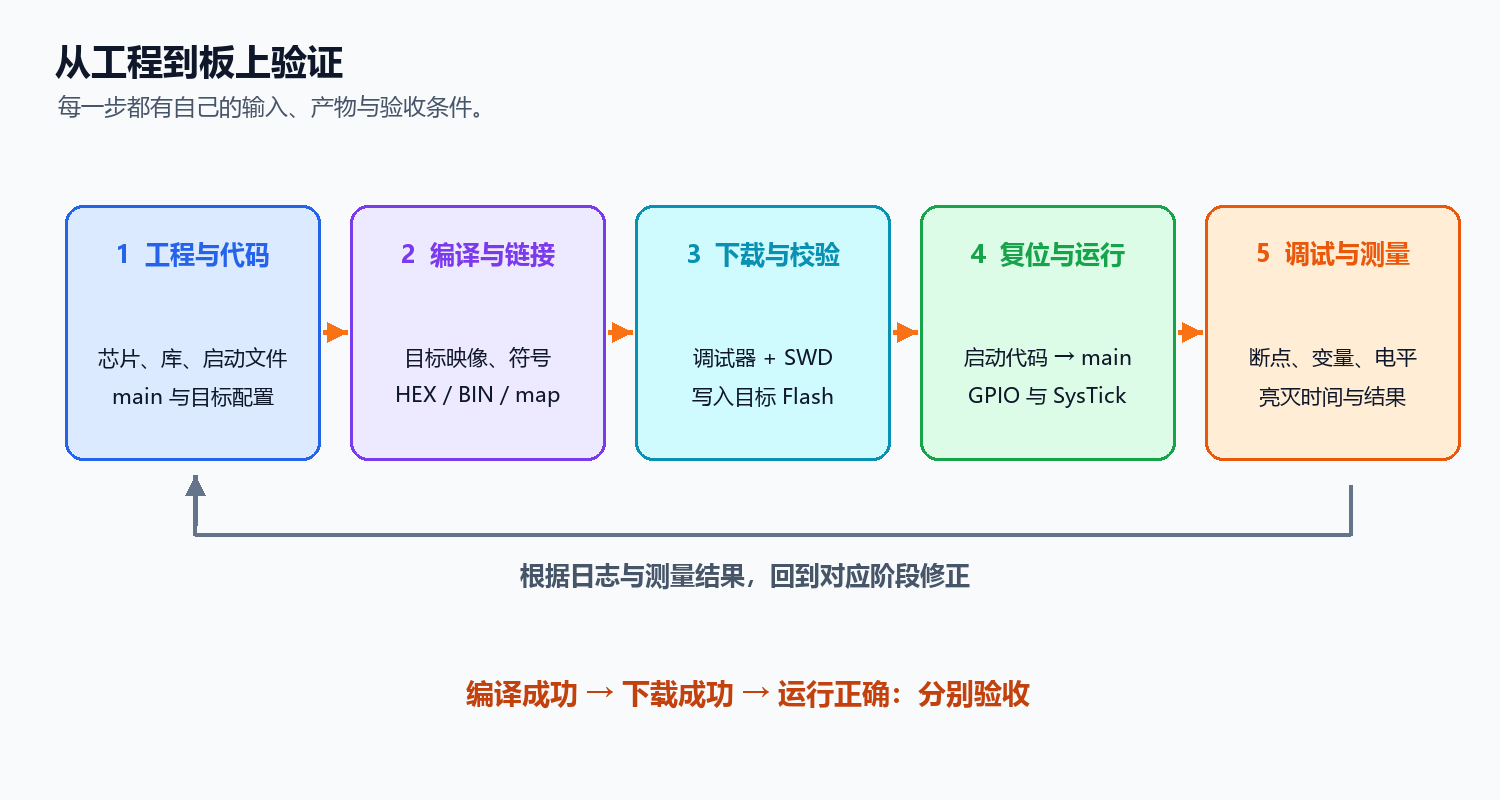

*自绘补充图：编译、下载、调试和硬件验证是不同步骤。*

| 阶段 | 输入 | 产出或观察结果 |
|---|---|---|
| 准备工程 | 型号、固件库、启动文件、配置 | 有效的项目结构与构建配置 |
| 写应用 | C 源文件、头文件 | 实现 LED 闪烁的逻辑 |
| 编译与链接 | 源码、汇编、库、内存布局 | 带地址与调试信息的目标映像 |
| 下载 | 固件、下载器、目标板 | 将程序写入目标 Flash |
| 复位运行 | 正确启动配置与供电 | MCU 从启动入口执行 |
| 调试验证 | 断点、变量、外设电平、时间 | 判断程序是否达到需求 |

编译成功表示源码和工程能生成目标映像；下载成功表示程序写入完成；运行正确还需要启动、时钟、外设和硬件匹配。

不要把三者混成“点了一次按钮所以实验成功”。例如固件可以编译通过，但 LED 引脚与板子不同；也可以下载成功，但 CPU 停在调试器断点处，暂时看不到闪烁。

本篇验收主线：**打开工程 → 编译零错误 → 连接芯片 → 下载并校验 → 复位运行 → 观察亮灭时间 → 断点解释代码。**


## 7. 开发工具分别负责什么

| 工具或组件 | 主要职责 | 不替代什么 |
|---|---|---|
| Keil MDK / µVision | 项目管理、编辑、构建调用、调试界面 | 不自动提供所有芯片外设源码 |
| Arm Compiler | 把 C/汇编等转成目标代码，并完成相关链接流程 | 不提供具体板子的接线定义 |
| Device Family Pack（DFP） | 器件描述、设备选择、调试/下载支持等，内容视包而定 | 不等同于完整应用工程 |
| GD32F4xx 固件库 | 寄存器定义、外设函数与模板/示例等 | 不自动配置你的工程全部选项 |
| CMSIS-DAP / DAPLink 调试器 | 让电脑通过调试协议访问目标 MCU | 不是通用 USB 转串口驱动 |
| USB-UART 桥与驱动 | 建立串口通信通道 | 通常不能代替 SWD 调试通道 |
| 烧录工具 | 打开固件并写入芯片 | 下载单独映像不等于具备源码级调试 |

课程使用的 DAPLink 设备还配合串口接口和供电功能；这些是具体硬件的能力组合。其他 CMSIS-DAP 设备未必都有串口、同样的供电引脚或相同接线颜色。

“CMSIS-DAP”是调试访问协议相关接口，“CMSIS”是更广的软件接口标准体系，两者有关联但不能混为一个固件库目录。


## 8. 环境版本：先建立可复现的组合

课程环境页提供的历史示例包括：

| 项目 | 课程页面中的名称或版本 | 本篇的使用说明 |
|---|---|---|
| Keil 安装包 | MDK538a.EXE，即 MDK 5.38a | 是课程当时的环境，不声称为目前最新版本 |
| 芯片支持包 | GigaDevice.GD32F4xx_DFP.3.0.3.pack | 与目标系列、工具版本兼容后使用 |
| 编译器 | Compiler 5（ARMCC），页面说明为可选 | 老工程可能依赖，现代工程也可能用 Compiler 6 |
| 固件库 | 页面出现 V3.0.0 和 V3.2.0 | 截图与附件版本不同，实际工程应选定同一套来源 |

Compiler 5 和 Compiler 6 的前端、汇编语法、编译选项与兼容细节不同。若课程模板来自 Compiler 5，先按它的原配置理解并建立基线；迁移到 6 时查看官方移植说明、选项与启动文件兼容性。

课程有“选择 Compiler 5 可规避很多警告”的提示。本篇把它理解为旧模板的环境匹配建议，不把“换版本以隐藏警告”作为一般修复方法。警告可能指出实际类型、声明或语法问题，需要看原因。

### 建议的环境记录

```text
开发板 / 芯片：实际填写，例如 GD32F407VET6
IDE：实际版本
Compiler：实际版本与工具链名称
DFP：实际包版本
Firmware Library：实际库版本
启动文件：实际文件名与适用工具链
外部晶振：实物/原理图确认值
系统时钟：工程预期值
调试器：型号、固件及驱动
```

课程版本并非一定要逐个升级。优先形成兼容且可记录的组合，再根据实际需求升级并验证。


## 9. Keil、支持包与驱动的准备流程

这是学习操作指南，本次没有执行安装。

1. 从官方渠道或课程明确给出的资料入口获取工具，按许可选择合法可用的版本。
2. 安装 MDK。课程建议工具路径使用简短英文目录，避免旧工具、脚本和路径处理的兼容问题。
3. 确认工程要求的编译器已安装，并在工程选项中可以选择；Compiler 5 按工程需求准备，不把它当作所有项目的必选项。
4. 安装 GD32F4xx 对应 DFP。可以在 Pack Installer 中在线安装，也可以导入可信来源的离线 `.pack` 文件。
5. 在新建工程或 `Options for Target → Device` 中检查能否找到实际 GD32 器件。
6. 根据实际下载器与串口桥型号，准备需要的驱动。

菜单名会随 MDK 版本略有变化；“魔法棒”图标通常打开 `Options for Target`。理解选项用途比记住某个截图按钮坐标更可靠。

### 支持包安装验收

能看见 GigaDevice 厂商，说明相关器件描述可用；还应确认具体型号在列表中，并检查下载算法可选择。仅有厂商名字不等于目标型号的所有支持都已就绪。

课程用 CH340 驱动配合其串口功能。只有实际设备使用 CH340/CH341 等对应芯片时，才使用匹配驱动；CMSIS-DAP 调试接口和 COM 串口是两个需要分别识别的设备功能。

USB 数据线必须支持数据传输。只供电的线可能让指示灯亮起，却无法让电脑识别下载器。

新装工具后先用最小模板建立一次干净构建，不急于导入屏幕、文件系统和大量传感器模块。


## 10. CMSIS、SPL、HAL、BSP：按职责分层理解

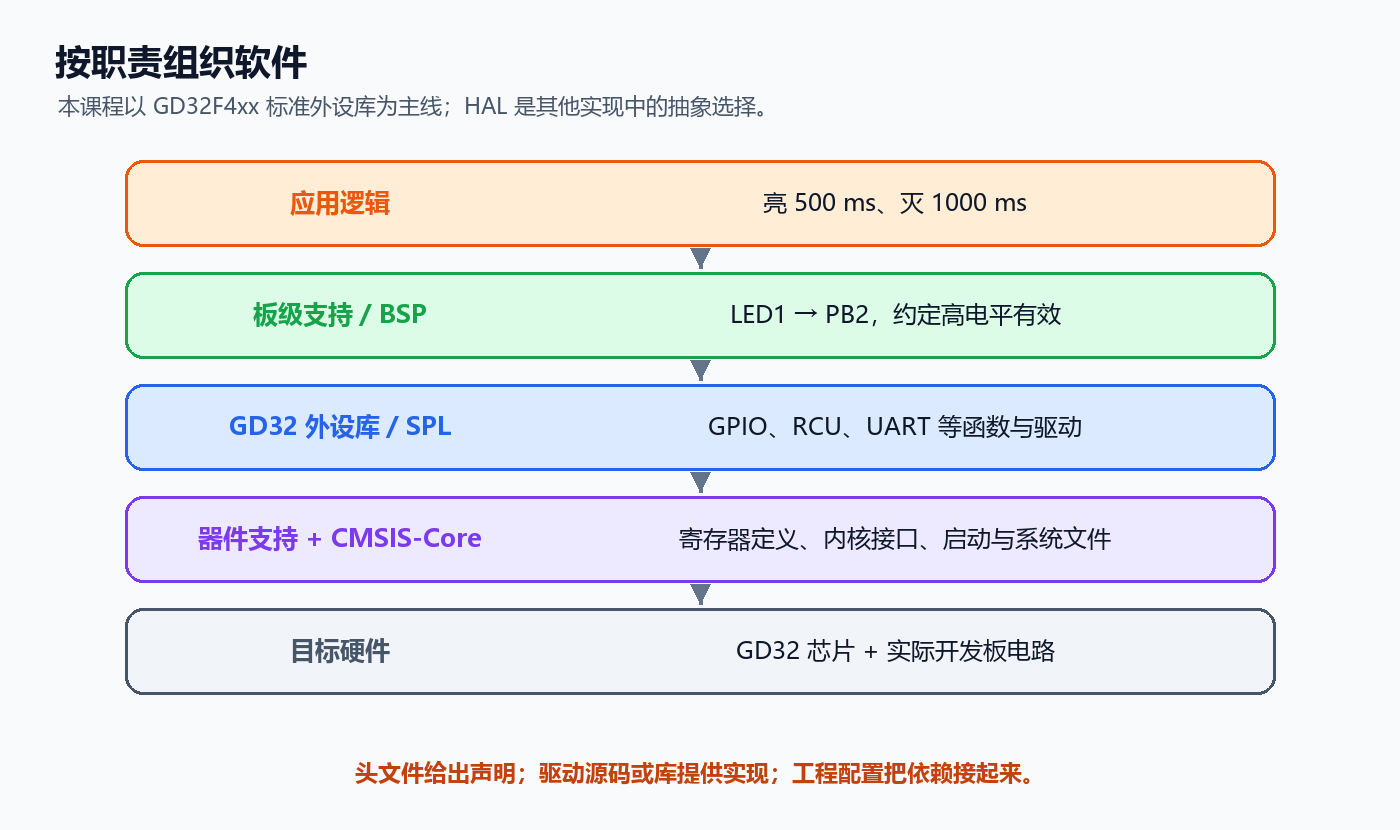

*自绘补充图：展示职责关系。不同 SDK 的实际层次和依赖方式可能不同。*

| 名称 | 主要解决什么问题 | 本课程对应 |
|---|---|---|
| CMSIS | Cortex 相关软件接口规范与组件，如内核寄存器访问和设备支持约定 | 内核头文件、器件支持与启动相关文件 |
| SPL / 标准外设库 | 封装某个芯片系列的外设寄存器操作 | GD32F4xx 的 gpio、rcu、usart 等驱动 |
| HAL | 硬件抽象接口，具体实现依厂商/框架而定 | 作为软件分层概念理解，不在本篇改写成另一套库 |
| BSP | 适配具体开发板的引脚、器件和初始化 | LED1 对应 PB2、板载器件接口 |
| 应用层 | 实现需求与业务流程 | LED 亮 500 ms、灭 1000 ms |
| C 标准库 | 通用语言库功能 | memcpy、printf、malloc 等 |

CMSIS 不只是一批汇编文件，也不会把不同厂商的所有外设 API 统一成完全相同的调用。标准外设库与 C 标准库是不同概念。

HAL 不一定建立在 SPL 之上，也不能保证换厂商以后完全不修改代码。移植仍需检查 API、外设特性、引脚、时钟和行为约束；分层能降低影响范围。

课程提到 MSP。该缩写在不同框架中用法并不一致，在一些 HAL 框架中指外设底层初始化支持；在 Cortex-M 文档中 MSP 还常指 Main Stack Pointer（主堆栈指针）。看到缩写时先看上下文，不把它当作所有工程都有相同含义的目录层。

本篇继续使用课程的 GD32F4xx SPL 主线。第 04 篇再建立更完整的 GPIO 板级封装。


## 11. 从官方固件库认识模板目录

课程固件库页面把发布包大致分成以下目录：

| 目录 | 内容 | 使用方法 |
|---|---|---|
| Examples | 厂商外设示例 | 找相应外设的初始化与应用方法 |
| Firmware | CMSIS、外设库、USB 库等 | 为工程提供匹配版本的头文件和实现 |
| Template | 不同工具链的模板工程 | 选择当前工具链与目标系列匹配的模板 |
| Utilities | 配套板文件或组件等 | 按实际需要选择，避免误用其他评估板定义 |

具体大小写和层级以实际压缩包为准。发布包中放着某个 `.c` 文件，不意味着它已经参与当前工程的构建。

### 常见工程目录组织

```text
GD32_LedDemo/
├─ Project/     工程文件、目标配置与构建输出
├─ Firmware/    匹配版本的内核/器件支持与外设库
├─ Hardware/    本板的驱动封装或 BSP
├─ User/        main、中断处理、基础延时等
└─ Doc/         型号、版本、引脚与操作说明
```

这是课程组织方式的概括，不要求每个工程使用相同名字。关键是让应用、板级适配和厂商文件容易区分。

Keil 左侧 Group 是**逻辑分组**，不是磁盘文件夹。把文件加进 Group 只是登记构建输入，不会自动搬动文件；仅在磁盘中新建文件夹也不会自动把其中源码加入编译。

使用相对路径有利于移动和复制工程。工程仍然引用原模板目录时，删除原目录后副本可能无法构建；复制以后要核对文件关联路径和 Include Paths。


## 12. 先使用模板，再理解每个关键文件

第一次练习可以复制课程提供的、与板子匹配的模板，并通过 `Project` 目录里的 `.uvprojx` 打开。先核对配置，不急于改动系统文件。

| 文件类型或常见文件 | 职责 | 缺失或错配的后果 |
|---|---|---|
| `.uvprojx` | Keil 工程、目标与文件关联 | 无法按模板配置构建 |
| 启动汇编 `startup_...s` | 向量表、复位入口与基础启动逻辑 | 启动/中断行为异常或链接冲突 |
| `system_gd32f4xx.c` | 系统时钟配置、SystemInit 等 | 时钟设置与频率声明不一致 |
| `gd32f4xx.h` | 器件寄存器、类型和配置等 | 外设定义缺失或与型号不符 |
| `gd32f4xx_gpio.c` | GPIO API 的实现 | 调用有声明却链接找不到实现 |
| `gd32f4xx_rcu.c` | 复位与时钟控制 API | 外设时钟函数链接失败 |
| `gd32f4xx_it.c` | 中断/异常处理函数 | 事件无处理、重复定义或落入默认处理 |
| `systick.c` / `.h` | 基础节拍与延时接口 | 延时卡住或单位不一致 |
| `main.c` | 应用入口与循环 | 主流程缺失或重复 main |

不同版本模板包含的文件名、宏和初始化位置可能不同。表中名字对应课程风格，不作为所有 MCU 工程的统一要求。

`startup`、`system`、`main` 不能随意从不同型号和工具链的模板拼接。尤其不要同时加入两个提供同名向量表或复位入口的启动文件。

头文件帮助编译器理解接口，源文件或库提供实际实现。**“能跳到声明”不等于“实现已经加入链接”。**


## 13. 手工搭建模板：把依赖逐项接起来

按照课程思路，手工创建一个最小 SPL 工程可以分为以下步骤：

1. 建立 Project、Firmware、User、Hardware、Doc 等目录。
2. 从选定版本的固件包复制必要的 CMSIS/器件支持和外设文件，保留其来源与版本说明。
3. 选取当前工具链对应的启动文件，以及匹配芯片的系统配置文件。
4. 从匹配模板引入 main、中断文件和基础延时文件，再清理不需要的应用逻辑。
5. 在 Keil 中新建工程，选择真实器件。以本篇主线为例选择对应 GD32F407VE，而不是环境安装页的 F450ZG。
6. 建立逻辑分组，加入启动汇编和各 C 文件。
7. 配置 Include Paths、器件相关宏、编译器与内存范围。
8. 添加需要的外设驱动；最小点灯至少包含实际调用的 GPIO、RCU 及模板依赖。
9. 配置调试器、Flash 下载算法和输出选项，执行一次完整构建。

课程模板说明还列出 `gd32f4xx_misc.c`。是否必须取决于当前模板和调用链，不能仅根据文件列表推断所有工程都需要同一组三个文件。

如果 Device Pack/RTE 已自动加入某些支持组件，手工复制版本前要核对是否重复。RTE 对话框里是否选择组件应由当前构建方式决定；课程采取手工管理文件，因此没有在该对话框中额外引入一套。

不要删除模板中暂时看不懂的中断和启动内容来“减少报错”。先识别是谁引用它，再决定精简范围。


## 14. 工程配置：哪些选项会真正改变结果

| 选项 | 作用 | 核对依据 |
|---|---|---|
| Device | 器件相关支持、调试和默认设置 | 芯片完整型号 |
| Compiler | 使用哪套工具链生成代码 | 模板需求与实际安装版本 |
| Define / 宏 | 条件编译、器件系列、库配置 | 当前固件库的说明和示例 |
| Include Paths | 查找被 include 的头文件 | 当前工程实际目录 |
| IROM / IRAM 或链接布局 | 代码和数据可以放在哪里 | 具体型号容量与内存图 |
| Output | 目标文件路径、HEX 等产物 | 下载与调试需求 |
| Debug | 调试器接口和连接参数 | 下载器类型、SWD 接线 |
| Utilities / Flash Download | 编程算法、擦除/下载/校验等 | 实际目标 Flash 与包支持 |

### 三种配置不要混为一谈

```text
Include Paths：解决“编译时从哪里找头文件”
工程源文件：解决“哪些实现要参与编译和链接”
链接内存布局：解决“生成的代码和数据放在哪里”
```

把某个 `.c` 所在目录加入 Include Paths，通常不会让它自动参与编译。仅加入头文件也不能解决外部函数找不到实现的链接错误。

不要给出一套通用 IROM/IRAM 数字套到全部 GD32F4xx。不同器件的容量、RAM 分区和可用范围可能不同；先核对数据手册，再检查模板是否使用了正确地址与大小。

课程的历史目录或行号随版本改变。需要改一个宏时按名字定位并阅读上下文，不把“注释第 65 行”当作所有版本的操作规则。


## 15. 从复位到 main：启动代码在做什么

典型 Cortex-M 裸机工程的启动过程可概括为：

```text
复位
→ 根据启动映射读取向量表中的初始栈指针与复位入口
→ Reset_Handler / 启动代码
→ 系统初始化与 C 运行时初始化
→ main
→ 应用主循环与中断响应
```

精确顺序由启动文件和运行库决定。很多模板在进入 main 前调用 SystemInit，并通过运行库完成 `.data` 初值建立、`.bss` 零初始化等步骤。

| 名称 | 主要用途 |
|---|---|
| 向量表 | 给复位和异常/中断提供入口信息 |
| 初始栈指针 | 为函数调用、局部存储与异常现场提供基础 |
| Reset_Handler | 复位后的软件入口 |
| SystemInit | 厂商定义的系统基础设置，通常涉及时钟 |
| C 运行时初始化 | 让静态对象与运行环境满足进入 C 代码的条件 |
| main | 应用程序开始执行的入口 |

普通局部对象和 malloc 生命周期与第 02 篇一致。下载到 Flash 的程序不能直接替代 RAM 中的初始化状态：每次复位需要重新建立相应运行环境。

中断函数名必须与启动向量的符号约定匹配。例如 `SysTick_Handler` 的大小写和拼写不同，可能导致你的函数没有接到真正的异常入口。中断细节在第 05 篇展开。

若调试时从未到达 main，应先检查启动入口、运行库、时钟等待和故障处理，而不是立即怀疑 LED 接线。


## 16. 晶振、系统时钟与 SystemCoreClock

时钟链路通常包含内部时钟、外部晶振、PLL、总线分频和外设时钟。CPU、总线和定时器频率未必相同。

| 项目 | 表示什么 | 常见误区 |
|---|---|---|
| 外部晶振频率 | 板上真实器件提供的参考时钟 | 修改宏不会把 8 MHz 晶振变成 25 MHz |
| HXTAL_VALUE 等宏 | 软件用于计算或配置的频率声明 | 它必须和实际板子相符 |
| PLL 与分频配置 | 如何得到系统/总线时钟 | 不能只改一个“目标频率”文字 |
| SystemCoreClock | 软件记录的内核频率值 | 变量值并非直接测量得到的硬件频率 |
| 外设时钟使能 | 是否给相应模块供时钟 | 全局时钟正常不等于 GPIO 时钟已开启 |

课程模板示例把外部晶振声明从 25 MHz 改成 8 MHz，并选择预期 168 MHz 的系统配置。这个改动只适用于相应板子、型号与模板，应核对 PLL、总线分频和存储器等待周期是否满足硬件条件。

课程中出现的声明示例：

```c
#define HXTAL_VALUE ((uint32_t)8000000)
```

这是软件声明片段，不是独立的时钟初始化程序。需要检查该版本库中哪个配置实际使用它，避免存在重复宏或改到未参与构建的副本。

### 三步核对时钟

1. 查原理图/实物，确认真实外部晶振频率。
2. 看当前 system 文件选择的时钟方案，检查目标型号、PLL 和分频约束。
3. 看 SystemCoreClock 的维护位置，并用调试信息或实际定时/时钟输出验证结果。

频率声明错误可能让延时、串口波特率和其他时序一起出问题。工程能编译并不会验证板上晶振与宏是否匹配。


## 17. SysTick 延时：配置、处理函数和单位必须对应

课程基础模板使用 SysTick 建立 1 ms 节拍，并提供 `systick_config()`、`delay_1ms()`、`delay_decrement()` 等接口。

典型配置片段：

```c
if (SysTick_Config(SystemCoreClock / 1000U)) {
    while (1) {
        // 捕获配置失败，具体工程可增加错误记录
    }
}
```

对常见的 CMSIS 实现，SysTick_Config 会按参数配置计数与中断并启动系统定时器；非零返回值表示参数不能按其规则配置。频率计算还要求 SystemCoreClock 正确且分频结果适用。

若内核时钟实际为 168 MHz：

```text
每毫秒计数 = 168000000 / 1000 = 168000
重装载值通常设置为 168000 - 1 = 167999
```

SysTick 为 24 位计数器，计数范围有限；CMSIS 帮助函数的参数与寄存器的重装载值并不完全是同一个数字。

### 递减延时的依赖链

```text
main 调用 delay_1ms(count)
→ 设置共享倒计数变量
→ SysTick 每 1 ms 触发
→ SysTick_Handler 调用 delay_decrement()
→ 倒计数到 0，delay_1ms 返回
```

共享计数变量通常声明为 volatile，让编译器按相应语义进行可观察访问。这里按模板约定在主循环中调用延时；volatile 并不会把该函数变成可重入、多任务安全的通用等待机制。

若没有配置 SysTick、全局中断被屏蔽、处理函数名错误或没有调用递减函数，delay_1ms 可能一直等待。复制延时代码时要把它的整条依赖链一起核对。


## 18. 为什么本篇先保留 1 ms 节拍

模板页面有一组可选改动：将 `SystemCoreClock / 1000U` 改为 `/ 1000000U`，在每个微秒递减，并把毫秒延时计数改为 `count * 1000`。

这不是只增加一个函数名，而是把系统节拍提高了 1000 倍。在 168 MHz 下，每微秒只有 168 个内核时钟周期，异常进入退出和处理函数就会消耗其中一部分，还会影响其他任务和中断。

| 方案 | 请求的 SysTick 事件频率 | 对本篇的意义 |
|---|---:|---|
| 基础 1 ms 节拍 | 1000 次/秒 | 已足够表达 LED 亮 500 ms、灭 1000 ms |
| 可选 1 µs 节拍 | 1000000 次/秒 | 需重新评估开销、可用性、精度与所有使用者 |

因此本篇示例按基础 1 ms 模板编写。不要只修改分频却保留旧计数单位，否则延时可能缩短 1000 倍；也不要只乘以 1000 却仍采用 1 ms 节拍，否则延时会被放大。

`count * 1000` 还可能发生整数溢出，需要给输入设范围。一个高频中断并不自动保证微秒级准确延时；更合适的硬件定时、计数方式和测量验证在定时器章节讨论。

递减式 delay 是阻塞等待：主循环暂时无法做其他工作，允许的中断仍可执行。不要在需要它所依赖的中断无法运行的上下文中调用，也不要把它作为所有异步任务的调度方案。


## 19. 读 LED 原理图：先确定引脚和有效电平

课程点灯页面的原理图显示：LED1 连接 PB2（图中同时标注 BOOT1），LED 支路经过 2 kΩ 电阻到 GND，PB2 还经 10 kΩ 电阻下拉到 GND。

在该图连接方式下，GPIO 输出高电平可使 LED 正向导通，输出低电平熄灭。因此本篇示例采用：

| 应用动作 | GPIO 操作 |
|---|---|
| LED1 亮 | PB2 输出高电平 |
| LED1 灭 | PB2 输出低电平 |

这是已查看的课程原理图结论，不保证所有板子 LED 都高电平有效。若 LED 从电源接到 GPIO，可能是低电平有效；若中间有晶体管或驱动芯片，还要检查控制极性。

**LED1 名称、PB2 引脚和 GPIOB 的第 2 位是不同层面的名称。**代码必须把它们正确对应起来。

PB2 上的 BOOT1 标注提示该引脚还可能参与启动相关功能，具体采样条件与启动配置查对应芯片手册。不要为了点灯随意改变启动跳线或与其他外设占用冲突。

若使用的是扩展板上的八个 LED，它们未必与核心板 LED1 共用这一路。先查看扩展板的接线，不能把本篇 PB2 示例直接当作八灯流水灯接口。


## 20. GPIO 初始化：先开时钟，再设模式与输出方式

课程的基础调用顺序是：GPIOB 时钟使能、PB2 输出模式、推挽与输出速度配置。下面做了小幅改写，在切换到输出前先设置预期的低电平输出锁存值。

```c
static void led1_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOB);
    gpio_bit_reset(GPIOB, GPIO_PIN_2);  // 准备初始关闭状态
    gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_2);
    gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_2);
}
```

这是使用 GD32F4xx SPL 的函数定义片段，前提是目标板与第 19 节接线一致，并且对应头文件和 gpio/rcu 实现已加入工程。

| API 或参数 | 此处用途 |
|---|---|
| `RCU_GPIOB` | 给 GPIOB 模块提供外设时钟 |
| `GPIO_MODE_OUTPUT` | 把相应引脚设置为数字输出 |
| `GPIO_PUPD_NONE` | 不启用内部上拉或下拉 |
| `GPIO_OTYPE_PP` | 推挽输出 |
| `GPIO_OSPEED_2MHZ` | 输出速度档位，影响边沿能力等 |
| `GPIO_PIN_2` | 选择 PB2 对应的位掩码 |

`GPIO_PIN_2` 是库定义的选择掩码，不是随意填写十进制下标 2。使用库宏能让参数意图更清楚。

`GPIO_OSPEED_2MHZ` 不表示 LED 会以 2 MHz 闪烁，也不是 CPU 主频设置。亮灭频率由应用的电平变化和等待时间决定。

这个配置用于本篇基础 LED 验证。输入、开漏、上下拉、复用和不同负载的电气要求，在第 04 篇结合硬件展开。


## 21. LED 闪烁示例：基于已核对模板的 main.c

下面是一个可替换模板 main.c 的完整应用源文件。它不是脱离 SDK 即可独立构建的桌面程序。

使用前提：

1. 目标为本篇核对的 GD32F407 核心板，LED1 接 PB2 且高电平有效。
2. 已使用匹配的启动文件、system 文件、GD32F4xx SPL 和工程宏/路径。
3. 在进入 `systick_config()` 前，时钟已初始化，SystemCoreClock 与实际内核频率一致。
4. `systick.c` 提供基础 1 ms 的配置与延时；`gd32f4xx_it.c` 中有唯一的 SysTick_Handler，并调用 delay_decrement。

```c
#include "gd32f4xx.h"
#include "systick.h"

static void led1_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOB);
    gpio_bit_reset(GPIOB, GPIO_PIN_2);
    gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_2);
    gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_2);
}

static void led1_on(void)
{
    gpio_bit_set(GPIOB, GPIO_PIN_2);
}

static void led1_off(void)
{
    gpio_bit_reset(GPIOB, GPIO_PIN_2);
}

int main(void)
{
    systick_config();
    led1_init();

    while (1) {
        led1_on();
        delay_1ms(500U);
        led1_off();
        delay_1ms(1000U);
    }
}
```

中断文件需要保持以下对应关系，**已有定义时核对并修改原函数，不再新建同名函数**：

```c
void SysTick_Handler(void)
{
    delay_decrement();
}
```

该片段所在文件应包含声明 delay_decrement 的头文件。模板也可能在该函数里保留其他必要内容，应先理解其依赖。

预期：初始化后 LED 进入循环，亮约 0.5 秒、灭约 1 秒。名义周期为 1.5 秒，频率约 0.667 Hz，占空比约 33.3%；实际还包含循环、调用和节拍相位等影响，应通过测量确认。

本例封装 led1_on/off，是把应用动作与有效电平分开表达。若换成低电平有效板子，核对引脚后修改板级函数，主循环仍可以保持直观。


## 22. 编译、链接和固件产物

第一次建立模板后先执行完整构建，之后增量 Build 可只重建改变的内容。修改工具链、关键宏或构建配置后，Rebuild 有助于避免把旧中间产物误当成新结果。

| 文件或信息 | 常见用途 |
|---|---|
| `.o` / 目标文件 | 各源文件编译后的中间结果 |
| `.axf` 等目标映像 | 通常包含地址、符号与调试信息，用于加载和源码调试 |
| `.hex` | 文本格式的固件记录，携带地址信息 |
| `.bin` | 原始字节序列，通常需要工具另外指定加载地址 |
| map / 链接映射 | 看符号、区段与内存分配 |
| 构建日志 | 区分编译、汇编、链接阶段的错误 |

产物名称与格式取决于工具链和选项。HEX 不是“十六进制显示的源代码”，BIN 也不会自动包含芯片型号和所有地址布局信息。

若需要导出 HEX，在 `Options for Target → Output` 检查 `Create HEX File` 等相应选项，并确认实际输出目录。Keil 内置下载通常使用工程生成的目标映像，不要求先手动打开 HEX。

下载前核对文件路径和修改时间，避免向芯片写入另一个实验的旧固件。复制模板后，输出目录仍指向旧路径也会造成混淆。

### 构建验收

```text
没有错误
→ 所有警告已理解并处理到合理状态
→ 链接布局与芯片容量匹配
→ 产物来自当前工程和当前构建
```

常见 `Code / RO-data / RW-data / ZI-data` 信息帮助判断存储需求，但不能机械地当作准确的 Flash/RAM 总占用公式。加载区、执行区、运行库、栈和堆等还要结合 map 与链接配置核对。


## 23. SWD、串口和供电：三条不同的连接

课程的 DAPLink 接线表可整理如下。线色仅是课程设备示例，真正应核对接口丝印和功能。

| 下载器侧 | 核心板侧标注 | 用途 | 本篇点灯是否需要 |
|---|---|---|---|
| SWDIO | DIO | SWD 双向数据 | 下载/调试需要 |
| SWCLK | CLK | SWD 时钟 | 下载/调试需要 |
| GND | GND | 共同参考地 | 需要 |
| 课程设备 5V 输出 | 5V0 | 通过板上电源电路供电 | 采用这种供电方式时需要 |
| RXD | U0T | 下载器接收 MCU 的串口发送 | 单纯 SWD 点灯不依赖 |
| TXD | U0R | 下载器发送到 MCU 串口接收 | 单纯 SWD 点灯不依赖 |

### 供电电压不等于信号电平

课程的 5V 线接开发板 5V0 电源入口，不是把 5V 接到 SWDIO、SWCLK 或普通 GPIO 上。板上稳压电路把输入电源转换为芯片需要的电压；实际容限查板卡和芯片资料。

一些通用调试器有 VTref 引脚，用于感知目标 I/O 参考电压，不是向目标供电的 5V 输出。不要根据引脚位置或线色推断用途。

接线时按板卡说明断电核对，避免排针错位、核心板反插和多个电源直接对接。课程自检页特别提示不要把带裸露焊点的板子放在金属物上通电，以免短路；使用绝缘表面即可。

UART 的 TX 接对方 RX，RX 接对方 TX，并且需要共地与兼容电平。SWDIO/CLK 则按同名功能连接，不应用串口交叉规则。

下载器是否另有 NRST、目标电压感知及复位连接，要看实际硬件。课程六线接法不是所有调试器的通用标准。


## 24. 在 Keil 中连接、下载、复位运行

按当前版本界面执行以下流程：

1. 打开当前工程，检查 Device 与刚生成的目标映像。
2. 在 `Options for Target → Debug` 选择与设备匹配的 CMSIS-DAP 调试器。
3. 进入调试器设置，选择 SWD 并确认能识别到连接的调试器与目标；连接不稳时适当降低 SWD 时钟。
4. 在 Utilities / Flash Download 等相关配置中检查下载算法，确保它覆盖实际芯片 Flash。
5. 设置需要的擦除、编程、校验选项。下载行为会替换目标上的相应固件，实际操作前明确当前实验对象。
6. 执行 Download，查看完整日志，确认没有连接、算法或校验错误。
7. 按 RESET 或使用工程支持的 Reset and Run 设置，让新固件运行。
8. 观察 LED 是否按设定亮灭；如果在调试会话中，检查 CPU 是否仍处于暂停状态。

### 分清 Reset、Run 与 Download

| 操作 | 主要效果 |
|---|---|
| Download | 写入目标程序，不保证此刻已经自由运行 |
| Reset | 让芯片或处理器按所用复位机制重新开始 |
| Run / Continue | 从当前暂停状态继续执行 |
| Stop / Halt | 暂停处理器供检查，影响应用时序 |

连接超时或找不到芯片时先检查 USB、供电、SWDIO/CLK、共地、目标选择和连接速度，再考虑固件是否占用了调试相关资源。不要把擦除保护、修改安全设置等操作当作普通连接问题的第一步。

本次未进行这些硬件操作；这里是实验执行流程，不代表用户电脑和板子已配置完成。


## 25. 基础调试：断点帮助回答“执行到哪里了”

在编译与下载链路正常后，进入调试会话可以检查程序路径和数据。

| 手段 | 适合回答的问题 |
|---|---|
| 断点 | CPU 是否到达 main、初始化或循环？ |
| 单步进入 | 被调用函数如何执行？ |
| 单步跳过 | 调用完成后状态是否符合预期？ |
| Watch / 变量窗口 | 变量当前是什么值，是否变化？ |
| 寄存器与外设窗口 | 配置位或输出状态是否按预期改变？ |
| 逻辑分析仪/示波器等外部测量 | 引脚实际电平、时间和波形是什么？ |

### 点灯程序的调试顺序

1. 在 main 设置断点，确认启动链路到达应用。
2. 运行到 led1_init 后，检查 GPIOB 时钟、PB2 输出模式与配置。
3. 分别停在 led1_on/off 后，观察输出状态与 LED。
4. 若卡在 delay_1ms，核对 SysTick 配置、中断入口和倒计数是否递减。
5. 清除或关闭影响时序的断点，连续运行，再测量亮灭周期。

在延时内部频繁单步会扭曲时间，暂停 CPU 时部分外设是否继续运行还取决于调试冻结配置。因此不能用“按了几次单步”去验证精确的 500 ms。

优化可能使变量显示为不可用，或让源代码行与机器执行不一一对应。学习时可使用适合调试的构建配置，完成逻辑验证后再评估发布配置。

如果停在默认异常处理或 HardFault，不要立即无限重试下载。记录位置、调用关系和故障信息，再检查错误地址访问、栈使用与初始化。详细异常分析在后续章节展开。


## 26. 自检固件与独立烧录工具的作用

课程的开发板自检页提供自检固件与 GD-Link Programmer 的使用流程，用来先检查板载资源和连接。

| 方法 | 适合用途 |
|---|---|
| 已知匹配的自检固件 | 分离硬件故障与自己应用代码的问题 |
| Keil 工程下载 | 在开发过程中编译、下载并进行源码调试 |
| 独立烧录工具 | 把选定的 HEX/BIN 写入板子，或执行厂商支持的编程操作 |

课程页面步骤为 `Target → Connect`、`File → Open`、`Target → Program`，成功后复位。具体界面、调试器兼容性和支持算法随工具版本改变；能否使用课程 DAPLink 也应以实际工具识别结果为准。

打开 BIN 时特别核对加载地址；HEX 携带地址信息，但仍要确认型号与固件用途。自检固件也需要匹配核心板、扩展板版本及屏幕等资源。

自检通过意味着该固件覆盖的功能在本次条件下工作，并不保证所有引脚和全部外设配置永远正确。自检失败也不直接等于芯片损坏：供电、接线、屏幕型号和固件匹配都可能影响结果。

编写新实验前记录板子当前运行哪个固件。自检固件和自己的 LED 固件会相互替换，不把前一次亮灯结果当作新程序运行的证据。


## 27. 常见错误：按发生阶段排查

| 阶段 | 现象 | 优先检查 |
|---|---|---|
| 工程打开 | 提示更新 Device 或旧项目格式 | 重新核对器件，按版本说明迁移工程格式 |
| 文件识别 | `FCARM - Output Name not specified` | C 文件是否误识别为 Image，汇编文件是否为 Assembly 类型 |
| 编译 | 找不到 gd32f4xx.h / systick.h | Include Paths、文件位置与使用的库版本 |
| 编译 | GPIO、RCU 宏未定义 | 头文件、条件编译宏、系列与 SDK 是否一致 |
| 汇编 | 启动文件语法不兼容 | 启动文件是否匹配 Compiler/工具链 |
| 链接 | Undefined symbol 某外设函数 | 对应 `.c` 或库是否加入当前目标 |
| 链接 | main / SysTick_Handler 重复定义 | 两份应用、重复中断文件或组件 |
| 链接 | 内存范围超出 | 实际型号容量、链接布局和资源占用 |
| 下载 | 找不到调试器 | USB 数据线、接口枚举、驱动与调试器选择 |
| 下载 | 找不到目标 MCU | 供电、共地、SWDIO/CLK、目标电压和速度 |
| 下载 | Flash 编程/校验失败 | 下载算法、地址范围、型号与供电稳定性 |
| 运行 | 下载成功但灯不闪 | CPU 暂停、未复位、启动配置、引脚与有效电平 |
| 运行 | 一直停在延时循环 | SysTick 中断、Handler、计数递减和单位 |
| 时序 | 延时/串口同时异常 | 真实晶振、PLL、分频与软件频率声明 |

课程指出 `.c` 文件可能误判为 Image file。先在文件选项中改为 C Source file；`.s` 应使用匹配的汇编文件类型。不要因为报错文本带 FCARM 就盲目填写一个输出名来掩盖识别问题。

旧 Keil 工程的迁移入口可能是 `Project → Manage → Migrate to Version 5 Format`。迁移后仍要重新核对 Device、Compiler、包与路径，不等于整个工程已经自动适配新环境。

一次只改变有证据指向的配置，保留构建和下载日志。系统时钟、芯片型号和启动文件一起乱改，会让错误来源更难定位。


## 28. 实验验收与可复用模板

把“我看见灯亮了”扩展为可重复的工程记录：

| 验收项 | 应能给出的证据 |
|---|---|
| 型号一致 | 板上芯片、Device、库与启动文件匹配 |
| 工程完整 | 换一个目录重新打开后能构建，不依赖遗失的外部路径 |
| 构建正确 | 当前工程生成目标映像，无未处理的构建错误 |
| 连接正常 | 工具能识别调试器与目标，下载和校验完成 |
| 启动正常 | 复位后能到 main，并进入应用循环 |
| 行为正确 | LED1 亮约 500 ms、灭约 1000 ms，连续循环 |
| 时序有依据 | 系统时钟与 SysTick 配置一致，实际波形可解释 |
| 文档可复现 | 版本、引脚、供电、下载方法和关键配置已记录 |

建议的模板说明内容：

```text
工程用途：基础 GD32 点灯模板
芯片与板卡：实际型号和版本
库与编译器：实际版本
时钟：晶振、目标内核频率与选择方案
引脚：LED1 -> PB2，高电平有效（仅适用于对应板）
延时：基础 SysTick 1 ms；Handler 调用 delay_decrement
下载：实际调试器，SWD，匹配的 Flash 算法
输出：实际目录与文件名
已验证：由学习者填写实际编译、下载和测量结果
已知限制：阻塞延时，未引入任务调度
```

模板保留厂商文件和配置来源，新增模块尽量放在应用/BSP 层。复制它开始下一篇实验前，再次检查当前实验的引脚是否冲突。

本笔记没有替用户完成上述硬件验收；表格是学习者实际实验时的完成标准。


## 29. 自测与练习

### 自测

1. ARM 架构、Cortex-M4、GD32F407VET6、开发板分别处于什么层次？
2. 安装 DFP 后能选择器件，是否意味着 GPIO 驱动源码已全部加入你的工程？
3. 把 GPIO 库头文件目录加入 Include Paths，能解决对应函数的 Undefined symbol 吗？
4. 本篇为什么不统一使用安装页面的 GD32F450ZG？
5. `GPIO_OSPEED_2MHZ` 决定 LED 闪烁频率吗？
6. 文件夹名称与 Keil Group 名称有什么区别？
7. main 之前一般有哪些启动工作？
8. 修改 HXTAL_VALUE 会改变板上的晶振实际频率吗？
9. 168 MHz 下基础 1 ms SysTick 的计数参数是多少？重装载值通常是多少？
10. 基础延时卡住，应该检查哪个中断处理函数和调用关系？
11. UART 的 RX/TX 与 SWDIO/SWCLK 是否采用同样的交叉接线规则？
12. HEX 和 BIN 的加载地址信息有什么区别？
13. 下载成功为什么不能直接证明 LED 实验完成？
14. 微秒节拍为什么需要重新评估中断开销和延时单位？

### 动手练习

1. 不修改项目，先列出自己的实际芯片、晶振、库、Compiler、DFP 和下载器，标出与课程示例不同的项。
2. 打开一个匹配模板，说明 main、启动文件、system 文件、GPIO/RCU 源码、SysTick Handler 各在哪里。
3. 完成 LED 亮 500 ms、灭 1000 ms；记录名义周期、占空比和实际测量值。
4. 改为亮 200 ms、灭 800 ms，先推导频率与占空比，再编译、下载和验证。
5. 复制模板到一个新的简短英文路径，重新打开并完整构建，检查没有引用旧项目路径。
6. 选择一个真实构建错误，说明它发生在编译还是链接，并写出直接依据。不要为练习故意改变供电或安全保护配置。

先能解释和复现基础链路，再引入屏幕、传感器、RTOS 等复杂模块。


## 30. 参考答案与一页复习

| 题号 | 参考答案 |
|---|---|
| 1 | 指令/执行约定、CPU 内核设计、具体 MCU、芯片与电路组成的板卡 |
| 2 | 不意味着；还需核对当前工程的源文件、组件和库依赖 |
| 3 | 通常不能；Include Paths 找声明，链接需要实现参与构建 |
| 4 | 课程核心板/手册与模板主线为 F407，页面型号混用时按实际芯片选择 |
| 5 | 不决定；它是输出速度档位，亮灭节奏由应用时序决定 |
| 6 | 文件夹管理磁盘文件，Group 管理工程内的逻辑分类与文件关联 |
| 7 | 向量/复位入口、栈、系统初始化与 C 运行时初值建立等，具体顺序看模板 |
| 8 | 不会；它是软件声明，必须与真实器件一致 |
| 9 | 参数 168000，常见实现写入重装载 167999 |
| 10 | SysTick_Handler 是否正确接入并调用 delay_decrement，SysTick 与中断是否运行 |
| 11 | 不同；UART 发接收交叉，SWD 按功能对应，均需合适参考地与电平 |
| 12 | HEX 记录含地址，原始 BIN 一般由工具另行指定加载地址 |
| 13 | 仍需复位/继续运行、正确启动、时钟、GPIO 和硬件接线 |
| 14 | 事件频率提高 1000 倍，CPU 预算与所有基于节拍的计数都会受影响 |

练习 3 的名义周期为 1.5 秒，频率约 0.667 Hz，占空比约 33.3%。练习 4 的名义周期为 1 秒，频率为 1 Hz，占空比为 20%。实际测量还需要考虑节拍与代码开销。

| 主题 | 一句话记住 |
|---|---|
| 芯片选择 | 以实际丝印、封装和手册为依据 |
| 支持包与库 | 器件支持、外设实现与工程配置分别核对 |
| 启动 | main 之前还要建立 CPU 和 C 运行环境 |
| 时钟 | 实物、配置和软件声明保持一致 |
| 点灯 | 引脚映射与有效电平来自原理图 |
| 下载 | 调试通道、串口和供电分别看待 |
| 调试 | 先判断执行路径，再检查配置与真实波形 |
| 复现 | 记录版本与连接，让下一次实验有可靠起点 |


## 31. 十二篇路线与本篇来源

| 编号 | 笔记主题 |
|---|---|
| 01 | C语言核心语法与函数 |
| 02 | C语言指针与内存 |
| **03** | **单片机入门与开发环境（本篇）** |
| 04 | GPIO与基础外设控制 |
| 05 | 中断与定时器 |
| 06 | 串口、DMA与通信模块 |
| 07 | 实时时钟与系统管理 |
| 08 | I2C与SPI通信 |
| 09 | ADC与传感器采集 |
| 10 | 存储器与文件系统 |
| 11 | 屏幕显示与触摸驱动 |
| 12 | LVGL图形界面开发 |

第 04 篇将从这里的模板出发，进一步整理 GPIO 的输入输出模式、按键与基础外设控制。

资料核对日期：2026-10-11。

| 分组 | 已阅读的课程页面 |
|---|---|
| 概述与内核 | [单片机概述](https://www.yuque.com/xxcls/mcu/ovn58fnkrhgq56hm)、[ARM介绍](https://www.yuque.com/xxcls/mcu/kzhfcxeye1egzted) |
| 环境与工程 | [开发环境搭建](https://www.yuque.com/xxcls/mcu/install_keil)、[高级点灯工程师](https://www.yuque.com/xxcls/mcu/mrfnizkrz7c17w73)、[库与包](https://www.yuque.com/xxcls/mcu/dg5k35eysm691qt2)、[模板工程的搭建](https://www.yuque.com/xxcls/mcu/it25rf0hzg6l7gef) |
| 支持资料 | [下载软件集合](https://www.yuque.com/xxcls/mcu/nc7ozto9xacge9uz)、[原理图、手册集合](https://www.yuque.com/xxcls/mcu/oxabwvsyncuudb4z)、[开发板自检](https://www.yuque.com/xxcls/mcu/yag6b86z2fcw6g7r) |

课程模板页面还给出官方资料入口：[GD32F4xx 用户手册检索](https://gd32mcu.com/cn/download/6?kw=GD32F4xx)、[GD32F407 资料检索](https://gd32mcu.com/cn/download?kw=GD32F407&lan=cn)。本次核对的是课程对这些资料的说明，未读取全部官方手册。

自绘图、结构化说明与示例为学习补充。本文已检查笔记文件、图片附件和关键时间算例，未安装开发工具、构建芯片工程或执行硬件下载与测量。
